In [1]:
import pandas as pd
import rdkit
from rdkit import Chem
from rdkit.Chem import rdRGroupDecomposition
from rdkit.Chem.Draw import IPythonConsole
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG, display
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.Chem import Draw, AllChem
from rdkit.Chem import rdDepictor
from itertools import product # for generating all possible combinations

#### Enter the Molecule of interest

In [31]:
parent_smiles = input("Enter the SMILES of the molecule: ")
mol = Chem.MolFromSmiles(parent_smiles)

if mol is None:
    print("Invalid Molecule")

else:
    print("________________________________")
    print("Hurray!! its a valid molecule")
    print(f"The entered SMILES is {parent_smiles}")
    print(f"Canonical SMILES: {Chem.MolToSmiles(mol)}")

Enter the SMILES of the molecule:  CC1(C)OB(OC1(C)C)C1=CC=C(C=C1)C1CC1(F)F


________________________________
Hurray!! its a valid molecule
The entered SMILES is CC1(C)OB(OC1(C)C)C1=CC=C(C=C1)C1CC1(F)F
Canonical SMILES: CC1(C)OB(c2ccc(C3CC3(F)F)cc2)OC1(C)C


#### Visualizing the molecule

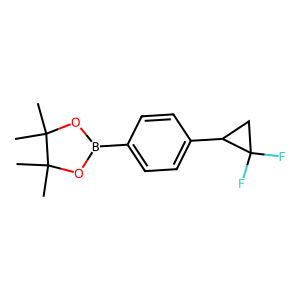

In [32]:
Draw.MolToImage(mol)

In [33]:
parent_mol = Chem.Mol(mol)
print(mol)
print(parent_mol)

In [34]:
def set_original_idx(mol):

    for atom in mol.GetAtoms():
        atom.SetIntProp("original_idx", atom.GetIdx())
        atom.SetProp("molAtomMapNumber", str(atom.GetIdx()))

    return mol

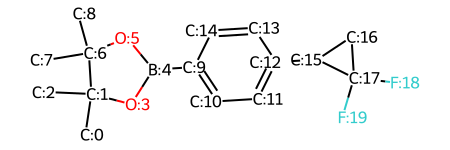

In [35]:
set_original_idx(parent_mol)

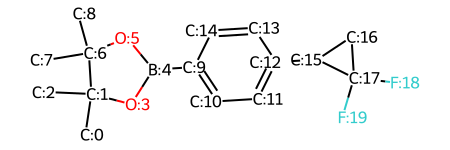

In [36]:
for bond in parent_mol.GetBonds():
    bond.SetIntProp("original_bond_idx", bond.GetIdx())
    bond.SetProp("molBondMapNumber", str(bond.GetIdx()))

parent_mol

#### Manual breaking of bonds

In [37]:
def find_current_idx(mol, original_idx):
    for atom in mol.GetAtoms():
        if atom.HasProp("original_idx"): 
            if atom.GetIntProp("original_idx") == original_idx:
                return atom.GetIdx()
    return None

In [38]:
def find_current_bond_idx(mol, original_bond_idx):
    for bond in mol.GetBonds():
        if bond.HasProp("original_bond_idx"):
            if bond.GetIntProp("original_bond_idx") == original_bond_idx:
                return bond.GetIdx()
    return None    

In [39]:
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import rdMolDraw2D
from rdkit.Geometry import Point2D
from IPython.display import SVG, display


def draw_with_original_bond_indices(mol, width=500, height=400):

    # Make sure the molecule has 2D coordinates
    if not mol.GetNumConformers():
        Chem.rdDepictor.Compute2DCoords(mol)

    # Create SVG drawer
    drawer = rdMolDraw2D.MolDraw2DSVG(width, height)

    # Drawing options
    opts = drawer.drawOptions()

    # Do not show RDKit's current bond indices
    opts.addBondIndices = False

    # Draw the molecule first
    drawer.DrawMolecule(mol)

    # Set font size for our bond numbers
    drawer.SetFontSize(14)

    # Set text colour
    drawer.SetColour((1.0, 0.0, 0.0))

    # Get 2D coordinates
    conf = mol.GetConformer()

    # Add original bond indices
    for bond in mol.GetBonds():

        # Check whether the bond has our original index
        if not bond.HasProp("original_bond_idx"):
            continue

        original_idx = bond.GetIntProp("original_bond_idx")

        # Get the two atoms connected by this bond
        atom1_idx = bond.GetBeginAtomIdx()
        atom2_idx = bond.GetEndAtomIdx()

        pos1 = conf.GetAtomPosition(atom1_idx)
        pos2 = conf.GetAtomPosition(atom2_idx)

        # Calculate midpoint of the bond
        mid_x = (pos1.x + pos2.x) / 2
        mid_y = (pos1.y + pos2.y) / 2

        # Calculate bond direction
        dx = pos2.x - pos1.x
        dy = pos2.y - pos1.y

        # Calculate bond length
        length = (dx**2 + dy**2) ** 0.5

        if length != 0:

            # Perpendicular direction
            perp_x = -dy / length
            perp_y = dx / length

            # Move label slightly away from the bond
            offset = 0.15

            label_x = mid_x + perp_x * offset
            label_y = mid_y + perp_y * offset

        else:
            label_x = mid_x
            label_y = mid_y

        # Position for label
        label_position = Point2D(label_x, label_y)

        # Draw original bond number
        drawer.DrawString(
            str(original_idx),
            label_position
        )

    # Finish drawing
    drawer.FinishDrawing()

    # Get SVG
    svg = drawer.GetDrawingText()

    # Display
    display(SVG(svg))

In [40]:
def get_core_dummy_info(mol):
    result = []

    for atom in mol.GetAtoms():

        if atom.GetSymbol() == "*":

            neighbor_data = {
                "core_dummy_current_idx": atom.GetIdx(),            
                "core_dummy_neighbor_current_idx": None,
                "core_dummy_neighbor_original_idx": None
            }

            neighbors = atom.GetNeighbors()

            if len(neighbors) > 0:
                neighbor = neighbors[0]

                neighbor_data["core_dummy_neighbor_current_idx"] = neighbor.GetIdx()

                if neighbor.HasProp("original_idx"):
                    neighbor_data["core_dummy_neighbor_original_idx"] = neighbor.GetIntProp("original_idx")

            result.append(neighbor_data)

    return result      

#### Replacement groups as dummy atoms

In [41]:
def get_replacement_dummy_info(mol):
    """
    Replacement groups are expected to contain exactly one dummy atom.
    """

    result = []

    for atom in mol.GetAtoms():

        if atom.GetSymbol() == "*":
           
            neighbors = atom.GetNeighbors()
            
            neighbor = neighbors[0]
                
            result.append({
                "replacement_dummy_current_idx":
                atom.GetIdx(),
                "replacement_dummy_neighbor_current_idx":
                neighbor.GetIdx()
            })
        
            return result       

In [42]:

import requests
from rdkit import Chem


def check_pubchem(smiles):

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return {
            "SMILES": smiles,
            "Status": "Invalid SMILES",
            "CID": None,
            "PubChem_URL": None
        }

    canonical_smiles = Chem.MolToSmiles(
        mol,
        canonical=True,
        isomericSmiles=True
    )

    url = (
        "https://pubchem.ncbi.nlm.nih.gov/rest/pug/"
        "compound/fastidentity/smiles/cids/JSON"
    )

    try:
        response = requests.post(
            url,
            data={"smiles": canonical_smiles},
            params={"identity_type": "same_stereo_isotope"},
            timeout=30
        )

        if response.status_code == 404:
            return {
                "SMILES": canonical_smiles,
                "Status": "Not found in PubChem",
                "CID": None,
                "PubChem_URL": None
            }

        response.raise_for_status()

        data = response.json()

        cids = data.get(
            "IdentifierList", {}
        ).get("CID", [])

        if cids:
            return {
                "SMILES": canonical_smiles,
                "Status": "Found",
                "CID": cids,
                "PubChem_URL": [
                    f"https://pubchem.ncbi.nlm.nih.gov/compound/{cid}"
                    for cid in cids
                ]
            }

        return {
            "SMILES": canonical_smiles,
            "Status": "Not found in PubChem",
            "CID": None,
            "PubChem_URL": None
        }

    except requests.RequestException as e:
        return {
            "SMILES": canonical_smiles,
            "Status": "API Error",
            "CID": None,
            "PubChem_URL": None,
            "Error": str(e)
        }


In [43]:
replacement_groups = {

    # ============================================================
    # 1. HYDROGEN / ALKYL GROUPS
    # ============================================================
    "alkyl": {
        "methyl": "[*:1]C",
        "ethyl": "[*:1]CC",
        "n_propyl": "[*:1]CCC",
        "n_butyl": "[*:1]CCCC",
        "n_pentyl": "[*:1]CCCCC",
        "n_hexyl": "[*:1]CCCCCC",

        "isopropyl": "[*:1]C(C)C",
        "isobutyl": "[*:1]CC(C)C",
        "sec_butyl": "[*:1]C(C)CC",
        "tert_butyl": "[*:1]C(C)(C)C",

        "neopentyl": "[*:1]CC(C)(C)C",
        "2_methylbutyl": "[*:1]CC(C)CC",
        "3_methylbutyl": "[*:1]CCC(C)C",
    },


    # ============================================================
    # 2. CYCLOALKYL GROUPS
    # ============================================================
    "cycloalkyl": {
        "cyclopropyl": "[*:1]C1CC1",
        "cyclobutyl": "[*:1]C1CCC1",
        "cyclopentyl": "[*:1]C1CCCC1",
        "cyclohexyl": "[*:1]C1CCCCC1",
        "cycloheptyl": "[*:1]C1CCCCCC1",
        "cyclooctyl": "[*:1]C1CCCCCCC1",

        "cyclopropylmethyl": "[*:1]CC1CC1",
        "cyclobutylmethyl": "[*:1]CC1CCC1",
        "cyclopentylmethyl": "[*:1]CC1CCCC1",
        "cyclohexylmethyl": "[*:1]CC1CCCCC1",
    },


    # ============================================================
    # 3. ALKENYL / ALKYNYL GROUPS
    # ============================================================
    "alkenyl_alkynyl": {
        "vinyl": "[*:1]C=C",
        "allyl": "[*:1]CC=C",
        "propenyl": "[*:1]C=CC",
        "isopropenyl": "[*:1]C(C)=C",
        "butenyl": "[*:1]CCC=C",

        "ethynyl": "[*:1]C#C",
        "propynyl": "[*:1]CC#C",
        "butynyl": "[*:1]CCC#C",
    },


    # ============================================================
    # 4. HALOGENS
    # ============================================================
    "halogens": {
        "fluoro": "[*:1]F",
        "chloro": "[*:1]Cl",
        "bromo": "[*:1]Br",
        "iodo": "[*:1]I",
    },


    # ============================================================
    # 5. FLUOROALKYL GROUPS
    # ============================================================
    "fluoroalkyl": {
        "fluoromethyl": "[*:1]CF",
        "difluoromethyl": "[*:1]C(F)F",
        "trifluoromethyl": "[*:1]C(F)(F)F",

        "2_fluoroethyl": "[*:1]CCF",
        "2_difluoroethyl": "[*:1]CC(F)F",
        "2_trifluoroethyl": "[*:1]CC(F)(F)F",

        "pentafluoroethyl": "[*:1]C(F)(F)C(F)(F)F",
    },


    # ============================================================
    # 6. ALKOXY GROUPS
    # ============================================================
    "alkoxy": {
        "methoxy": "[*:1]OC",
        "ethoxy": "[*:1]OCC",
        "n_propoxy": "[*:1]OCCC",
        "isopropoxy": "[*:1]OC(C)C",
        "n_butoxy": "[*:1]OCCCC",
        "isobutoxy": "[*:1]OCC(C)C",
        "tert_butoxy": "[*:1]OC(C)(C)C",

        "cyclopropoxy": "[*:1]OC1CC1",
        "cyclobutoxy": "[*:1]OC1CCC1",
        "cyclopentoxy": "[*:1]OC1CCCC1",
        "cyclohexoxy": "[*:1]OC1CCCCC1",
    },


    # ============================================================
    # 7. FLUOROALKOXY
    # ============================================================
    "fluoroalkoxy": {
        "difluoromethoxy": "[*:1]OC(F)F",
        "trifluoromethoxy": "[*:1]OC(F)(F)F",
        "2_fluoroethoxy": "[*:1]OCCF",
        "2_difluoroethoxy": "[*:1]OCC(F)F",
    },


    # ============================================================
    # 8. HYDROXY / OXYGEN GROUPS
    # ============================================================
    "oxygen": {
        "hydroxy": "[*:1]O",
        "hydroxymethyl": "[*:1]CO",
        "methoxymethyl": "[*:1]COC",
        "ethoxymethyl": "[*:1]COCC",

        "acetoxy": "[*:1]OC(C)=O",
        "formyloxy": "[*:1]OC=O",
    },


    # ============================================================
    # 9. AMINE GROUPS
    # ============================================================
    "amines": {
        "amino": "[*:1]N",
        "methylamino": "[*:1]NC",
        "ethylamino": "[*:1]NCC",
        "propylamino": "[*:1]NCCC",
        "isopropylamino": "[*:1]NC(C)C",

        "dimethylamino": "[*:1]N(C)C",
        "diethylamino": "[*:1]N(CC)CC",
        "ethylmethylamino": "[*:1]N(C)CC",

        "cyclopropylamino": "[*:1]NC1CC1",
        "cyclobutylamino": "[*:1]NC1CCC1",
        "cyclopentylamino": "[*:1]NC1CCCC1",
        "cyclohexylamino": "[*:1]NC1CCCCC1",
    },


    # ============================================================
    # 10. AMIDES
    # ============================================================
    "amides": {
        "carboxamide": "[*:1]C(=O)N",
        "N_methylamide": "[*:1]C(=O)NC",
        "N_ethylamide": "[*:1]C(=O)NCC",
        "N_isopropylamide": "[*:1]C(=O)NC(C)C",
        "N,N_dimethylamide": "[*:1]C(=O)N(C)C",
        "N,N_diethylamide": "[*:1]C(=O)N(CC)CC",

        "N_cyclopropylamide": "[*:1]C(=O)NC1CC1",
        "N_cyclohexylamide": "[*:1]C(=O)NC1CCCCC1",
    },


    # ============================================================
    # 11. CARBONYL / ESTER GROUPS
    # ============================================================
    "carbonyl": {
        "formyl": "[*:1]C=O",
        "acetyl": "[*:1]C(C)=O",
        "propionyl": "[*:1]C(=O)CC",
        "butyryl": "[*:1]C(=O)CCC",

        "methyl_ester": "[*:1]C(=O)OC",
        "ethyl_ester": "[*:1]C(=O)OCC",
        "isopropyl_ester": "[*:1]C(=O)OC(C)C",

        "carboxylic_acid": "[*:1]C(=O)O",
    },


    # ============================================================
    # 12. NITRILE / CYANO
    # ============================================================
    "nitrile": {
        "cyano": "[*:1]C#N",
        "cyanomethyl": "[*:1]CC#N",
    },


    # ============================================================
    # 13. SULFUR GROUPS
    # ============================================================
    "sulfur": {
        "thiol": "[*:1]S",
        "methylthio": "[*:1]SC",
        "ethylthio": "[*:1]SCC",
        "propylthio": "[*:1]SCCC",

        "methylsulfoxide": "[*:1]S(=O)C",
        "ethylsulfoxide": "[*:1]S(=O)CC",

        "methylsulfone": "[*:1]S(=O)(=O)C",
        "ethylsulfone": "[*:1]S(=O)(=O)CC",

        "sulfonamide": "[*:1]S(=O)(=O)N",
        "N_methylsulfonamide": "[*:1]S(=O)(=O)NC",
        "N_ethylsulfonamide": "[*:1]S(=O)(=O)NCC",
        "N_N_dimethylsulfonamide": "[*:1]S(=O)(=O)N(C)C",
    },


    # ============================================================
    # 14. PHENYL / BENZYL
    # ============================================================
    "phenyl": {
        "phenyl": "[*:1]c1ccccc1",

        "benzyl": "[*:1]Cc1ccccc1",

        "tolyl": "[*:1]c1ccc(C)cc1",
        "anisyl": "[*:1]c1ccc(OC)cc1",

        "phenoxy": "[*:1]Oc1ccccc1",
        "phenethyl": "[*:1]CCc1ccccc1",
        "phenylpropyl": "[*:1]CCCc1ccccc1",
    },


    # ============================================================
    # 15. HALOPHENYL GROUPS
    # ============================================================
    "halophenyl": {
        "2_fluorophenyl": "[*:1]c1ccccc1F",
        "3_fluorophenyl": "[*:1]c1cccc(F)c1",
        "4_fluorophenyl": "[*:1]c1ccc(F)cc1",

        "2_chlorophenyl": "[*:1]c1ccccc1Cl",
        "3_chlorophenyl": "[*:1]c1cccc(Cl)c1",
        "4_chlorophenyl": "[*:1]c1ccc(Cl)cc1",

        "2_bromophenyl": "[*:1]c1ccccc1Br",
        "3_bromophenyl": "[*:1]c1cccc(Br)c1",
        "4_bromophenyl": "[*:1]c1ccc(Br)cc1",
    },


    # ============================================================
    # 16. SUBSTITUTED PHENYL
    # ============================================================
    "substituted_phenyl": {
        "2_methylphenyl": "[*:1]c1ccccc1C",
        "3_methylphenyl": "[*:1]c1cccc(C)c1",
        "4_methylphenyl": "[*:1]c1ccc(C)cc1",

        "2_methoxyphenyl": "[*:1]c1ccccc1OC",
        "3_methoxyphenyl": "[*:1]c1cccc(OC)c1",
        "4_methoxyphenyl": "[*:1]c1ccc(OC)cc1",

        "2_hydroxyphenyl": "[*:1]c1ccccc1O",
        "3_hydroxyphenyl": "[*:1]c1cccc(O)c1",
        "4_hydroxyphenyl": "[*:1]c1ccc(O)cc1",

        "2_trifluoromethylphenyl": "[*:1]c1ccccc1C(F)(F)F",
        "3_trifluoromethylphenyl": "[*:1]c1cccc(C(F)(F)F)c1",
        "4_trifluoromethylphenyl": "[*:1]c1ccc(C(F)(F)F)cc1",

        "2_aminophenyl": "[*:1]c1ccccc1N",
        "3_aminophenyl": "[*:1]c1cccc(N)c1",
        "4_aminophenyl": "[*:1]c1ccc(N)cc1",
    },


    # ============================================================
    # 17. PYRIDYL GROUPS
    # ============================================================
    "pyridyl": {
        "2_pyridyl": "[*:1]c1ccccn1",
        "3_pyridyl": "[*:1]c1cccnc1",
        "4_pyridyl": "[*:1]c1ccncc1",
    },


    # ============================================================
    # 18. PYRIMIDINYL / PYRAZINYL / PYRIDAZINYL
    # ============================================================
    "diazines": {
        "2_pyrimidinyl": "[*:1]c1nccnc1",
        "4_pyrimidinyl": "[*:1]c1ncc(nc1)",
        "2_pyrazinyl": "[*:1]c1cnccn1",
        "2_pyridazinyl": "[*:1]c1nnccc1",
    },


    # ============================================================
    # 19. FIVE-MEMBERED HETEROAROMATICS
    # ============================================================
    "five_membered_heteroaryl": {
        "2_furyl": "[*:1]c1ccoc1",
        "3_furyl": "[*:1]c1occc1",

        "2_thienyl": "[*:1]c1ccsc1",
        "3_thienyl": "[*:1]c1sccc1",

        "2_thiazolyl": "[*:1]c1ncsc1",
        "2_oxazolyl": "[*:1]c1ncco1",

        "2_imidazolyl": "[*:1]c1ncc[nH]1",
        "2_pyrazolyl": "[*:1]c1n[nH]cc1",

        "isoxazolyl": "[*:1]c1nocc1",
        "isothiazolyl": "[*:1]c1nscc1",
    },


    # ============================================================
    # 20. SATURATED HETEROCYCLES
    # ============================================================
    "saturated_heterocycles": {
        "morpholine": "[*:1]N1CCOCC1",
        "piperidine": "[*:1]N1CCCCC1",
        "pyrrolidine": "[*:1]N1CCCC1",
        "azetidine": "[*:1]N1CCC1",

        "tetrahydrofuran": "[*:1]C1CCOC1",
        "tetrahydropyran": "[*:1]C1CCOCC1",

        "piperazine": "[*:1]N1CCNCC1",
        "N_methylpiperazine": "[*:1]N1CCN(C)CC1",

        "imidazolidine": "[*:1]N1CCNC1",
        "oxazolidine": "[*:1]N1CCOC1",
    },


    # ============================================================
    # 21. UREA / GUANIDINE / RELATED GROUPS
    # ============================================================
    "nitrogen_carbonyl": {
        "urea": "[*:1]NC(=O)N",
        "N_methylurea": "[*:1]NC(=O)NC",
        "N_N_dimethylurea": "[*:1]NC(=O)N(C)C",

        "guanidine": "[*:1]NC(=N)N",
        "N_methylguanidine": "[*:1]NC(=N)NC",

        "hydrazide": "[*:1]C(=O)NN",
    },


    # ============================================================
    # 22. COMMON POLAR / IONIZABLE GROUPS
    # ============================================================
    "polar_groups": {
        "hydroxyl": "[*:1]O",
        "amino": "[*:1]N",
        "hydroxymethyl": "[*:1]CO",
        "aminomethyl": "[*:1]CN",
        "dimethylaminomethyl": "[*:1]CN(C)C",

        "nitro": "[*:1][N+](=O)[O-]",
        "nitroso": "[*:1]N=O",

        "sulfonamide": "[*:1]S(=O)(=O)N",
        "sulfonic_acid": "[*:1]S(=O)(=O)O",
    },


    # ============================================================
    # 23. BIOISOSTERIC / MEDICINAL-CHEMISTRY GROUPS
    # ============================================================
    "bioisosteres": {
        "tetrazole": "[*:1]c1nnn[nH]1",
        "1_2_4_triazole": "[*:1]c1nnc[nH]1",
        "1_2_3_triazole": "[*:1]c1nn[nH]c1",

        "oxadiazole": "[*:1]c1nnco1",
        "thiadiazole": "[*:1]c1nncs1",

        "imidazole": "[*:1]c1ncc[nH]1",
        "pyrazole": "[*:1]c1n[nH]cc1",
    },
}

In [44]:
invalid_groups = {}

for category, groups in replacement_groups.items():

    for name, smiles in groups.items():

        mol = Chem.MolFromSmiles(smiles)

        if mol is None:
            invalid_groups[f"{category}/{name}"] = smiles

print("Number of invalid fragments:", len(invalid_groups))

for name, smiles in invalid_groups.items():
    print(name, ":", smiles)

Number of invalid fragments: 0


methyl : [*:1]C


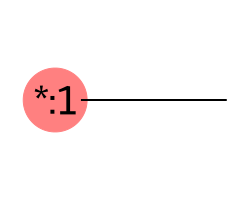

ethyl : [*:1]CC


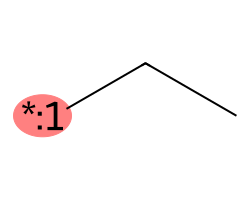

n_propyl : [*:1]CCC


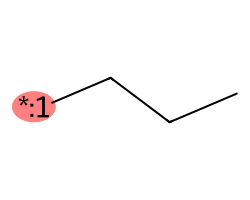

n_butyl : [*:1]CCCC


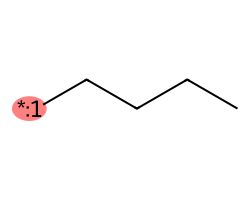

n_pentyl : [*:1]CCCCC


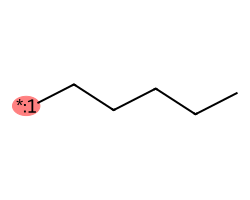

n_hexyl : [*:1]CCCCCC


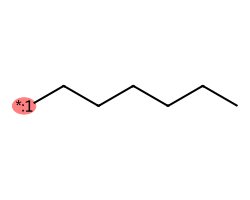

isopropyl : [*:1]C(C)C


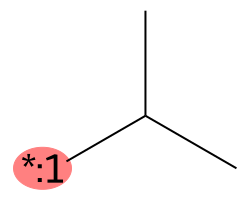

isobutyl : [*:1]CC(C)C


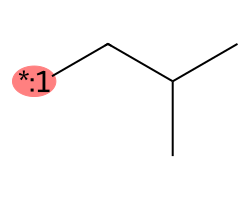

sec_butyl : [*:1]C(C)CC


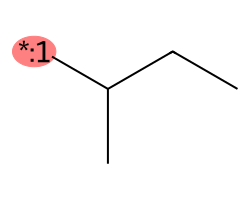

tert_butyl : [*:1]C(C)(C)C


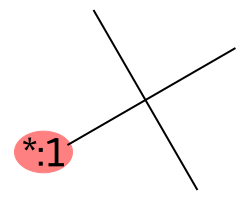

neopentyl : [*:1]CC(C)(C)C


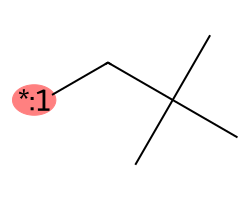

2_methylbutyl : [*:1]CC(C)CC


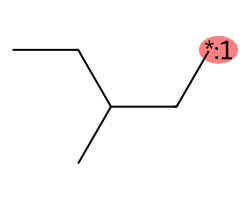

3_methylbutyl : [*:1]CCC(C)C


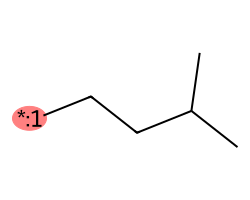

cyclopropyl : [*:1]C1CC1


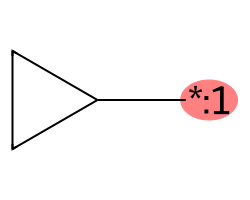

cyclobutyl : [*:1]C1CCC1


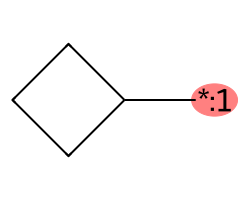

cyclopentyl : [*:1]C1CCCC1


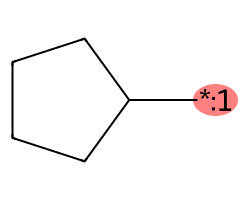

cyclohexyl : [*:1]C1CCCCC1


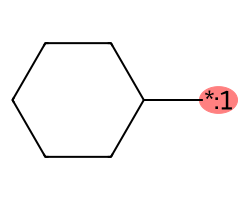

cycloheptyl : [*:1]C1CCCCCC1


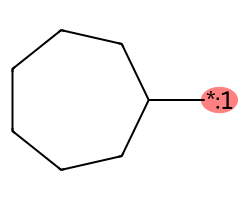

cyclooctyl : [*:1]C1CCCCCCC1


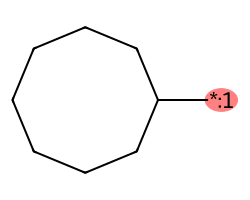

cyclopropylmethyl : [*:1]CC1CC1


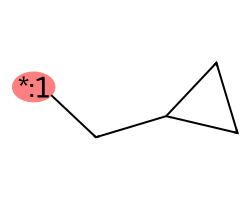

cyclobutylmethyl : [*:1]CC1CCC1


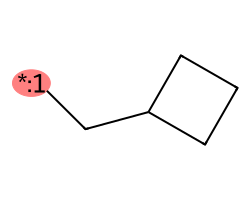

cyclopentylmethyl : [*:1]CC1CCCC1


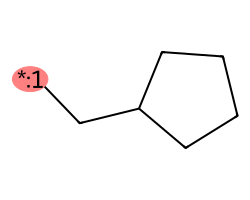

cyclohexylmethyl : [*:1]CC1CCCCC1


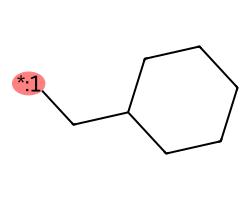

vinyl : [*:1]C=C


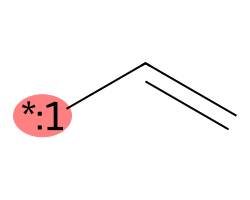

allyl : [*:1]CC=C


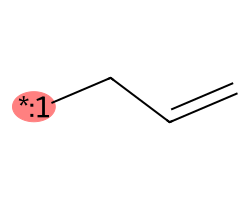

propenyl : [*:1]C=CC


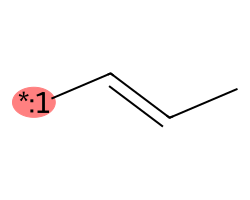

isopropenyl : [*:1]C(C)=C


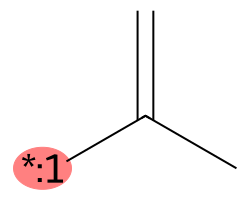

butenyl : [*:1]CCC=C


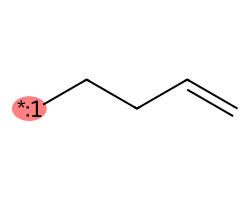

ethynyl : [*:1]C#C


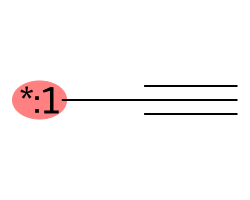

propynyl : [*:1]CC#C


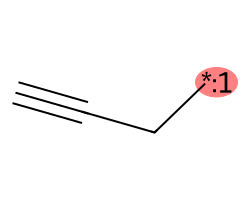

butynyl : [*:1]CCC#C


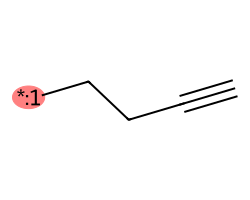

fluoro : [*:1]F


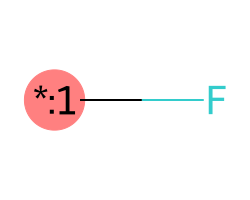

chloro : [*:1]Cl


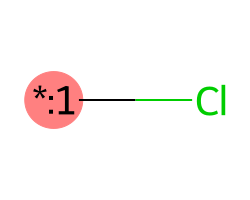

bromo : [*:1]Br


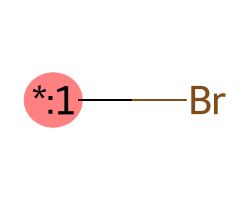

iodo : [*:1]I


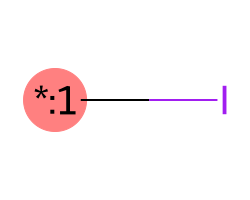

fluoromethyl : [*:1]CF


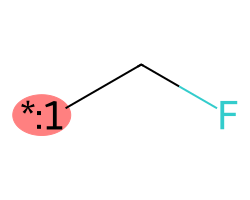

difluoromethyl : [*:1]C(F)F


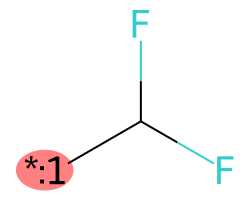

trifluoromethyl : [*:1]C(F)(F)F


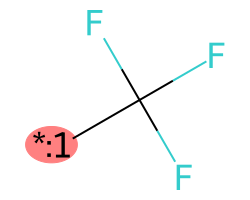

2_fluoroethyl : [*:1]CCF


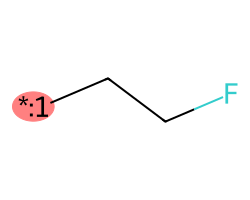

2_difluoroethyl : [*:1]CC(F)F


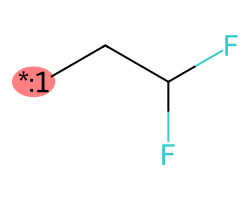

2_trifluoroethyl : [*:1]CC(F)(F)F


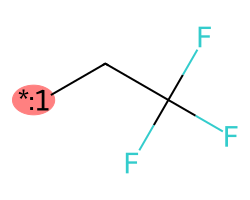

pentafluoroethyl : [*:1]C(F)(F)C(F)(F)F


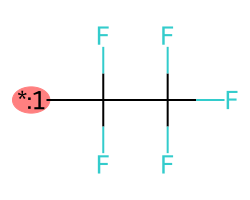

methoxy : [*:1]OC


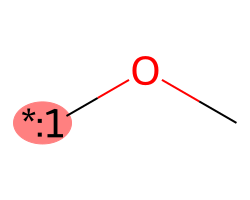

ethoxy : [*:1]OCC


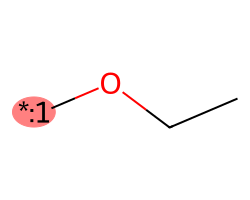

n_propoxy : [*:1]OCCC


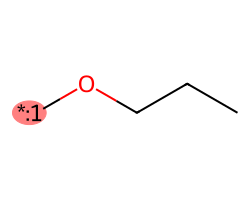

isopropoxy : [*:1]OC(C)C


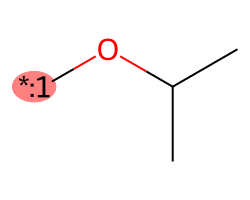

n_butoxy : [*:1]OCCCC


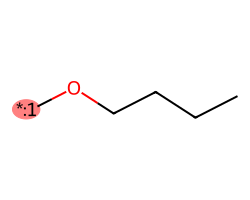

isobutoxy : [*:1]OCC(C)C


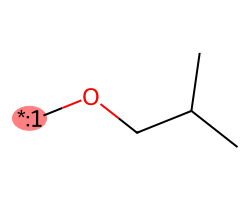

tert_butoxy : [*:1]OC(C)(C)C


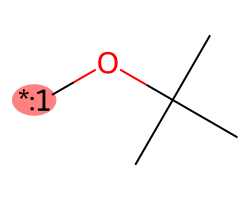

cyclopropoxy : [*:1]OC1CC1


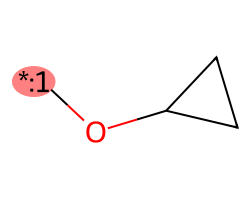

cyclobutoxy : [*:1]OC1CCC1


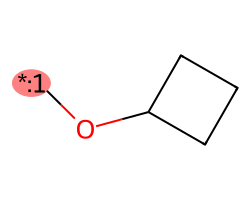

cyclopentoxy : [*:1]OC1CCCC1


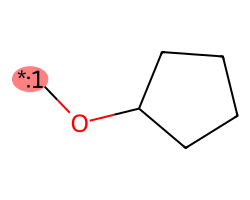

cyclohexoxy : [*:1]OC1CCCCC1


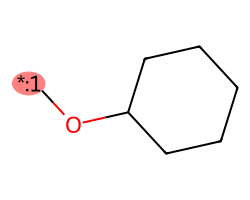

difluoromethoxy : [*:1]OC(F)F


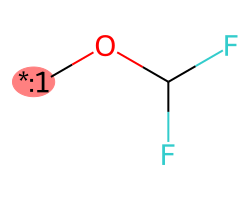

trifluoromethoxy : [*:1]OC(F)(F)F


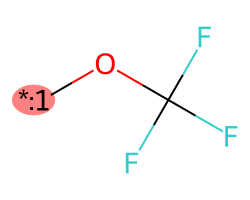

2_fluoroethoxy : [*:1]OCCF


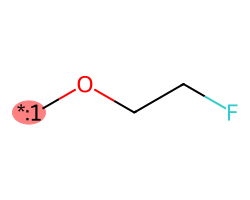

2_difluoroethoxy : [*:1]OCC(F)F


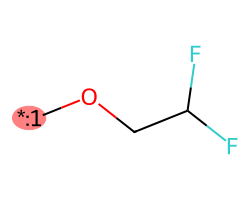

hydroxy : [*:1]O


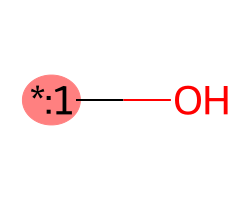

hydroxymethyl : [*:1]CO


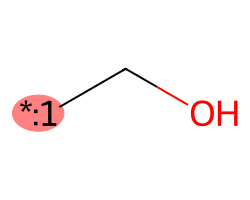

methoxymethyl : [*:1]COC


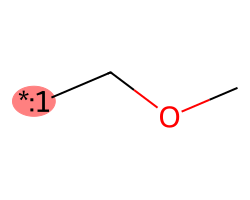

ethoxymethyl : [*:1]COCC


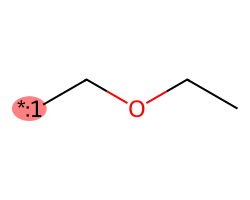

acetoxy : [*:1]OC(C)=O


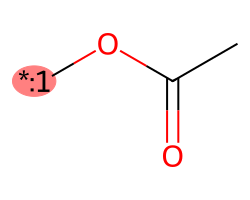

formyloxy : [*:1]OC=O


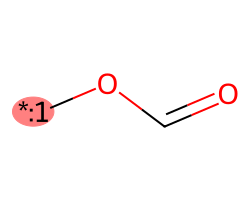

amino : [*:1]N


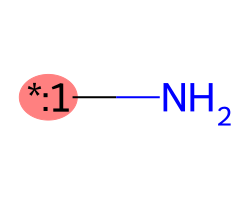

methylamino : [*:1]NC


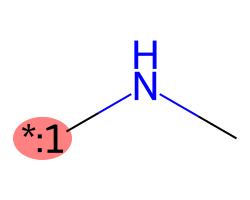

ethylamino : [*:1]NCC


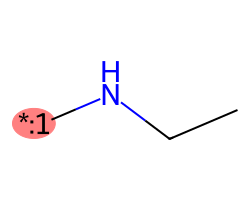

propylamino : [*:1]NCCC


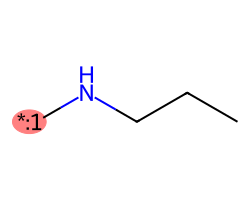

isopropylamino : [*:1]NC(C)C


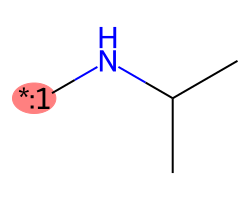

dimethylamino : [*:1]N(C)C


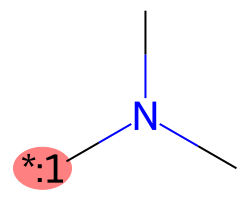

diethylamino : [*:1]N(CC)CC


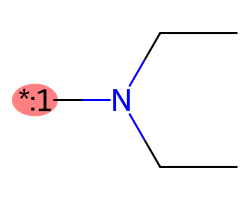

ethylmethylamino : [*:1]N(C)CC


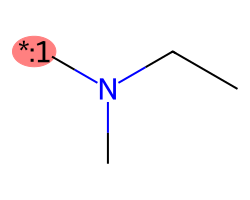

cyclopropylamino : [*:1]NC1CC1


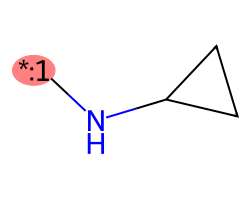

cyclobutylamino : [*:1]NC1CCC1


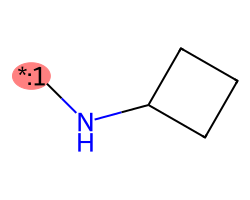

cyclopentylamino : [*:1]NC1CCCC1


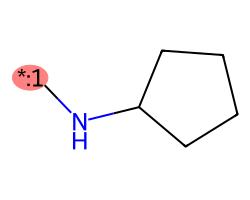

cyclohexylamino : [*:1]NC1CCCCC1


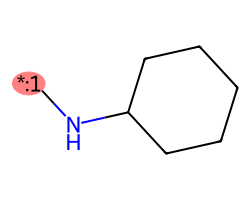

carboxamide : [*:1]C(=O)N


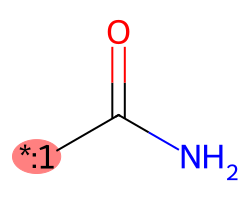

N_methylamide : [*:1]C(=O)NC


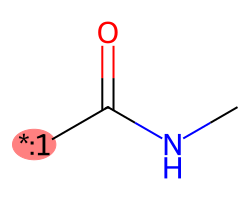

N_ethylamide : [*:1]C(=O)NCC


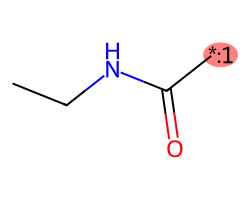

N_isopropylamide : [*:1]C(=O)NC(C)C


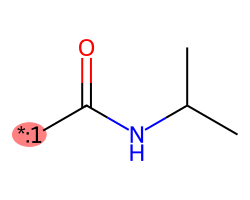

N,N_dimethylamide : [*:1]C(=O)N(C)C


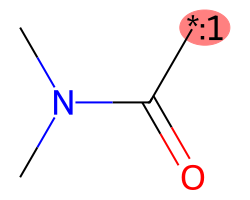

N,N_diethylamide : [*:1]C(=O)N(CC)CC


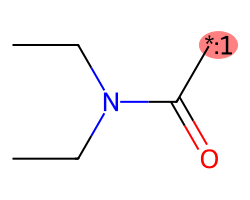

N_cyclopropylamide : [*:1]C(=O)NC1CC1


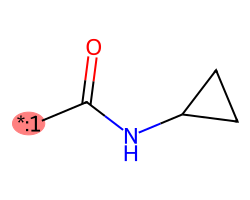

N_cyclohexylamide : [*:1]C(=O)NC1CCCCC1


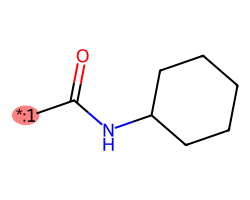

formyl : [*:1]C=O


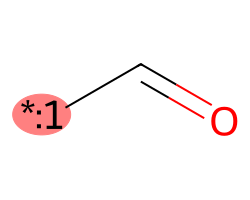

acetyl : [*:1]C(C)=O


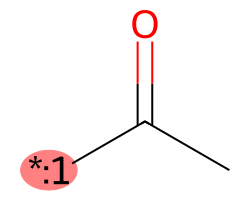

propionyl : [*:1]C(=O)CC


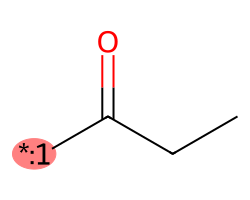

butyryl : [*:1]C(=O)CCC


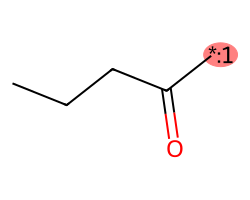

methyl_ester : [*:1]C(=O)OC


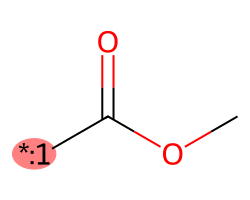

ethyl_ester : [*:1]C(=O)OCC


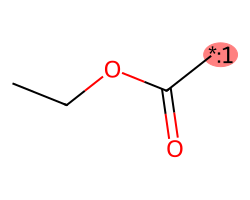

isopropyl_ester : [*:1]C(=O)OC(C)C


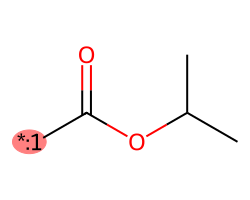

carboxylic_acid : [*:1]C(=O)O


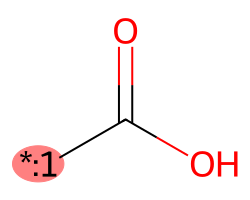

cyano : [*:1]C#N


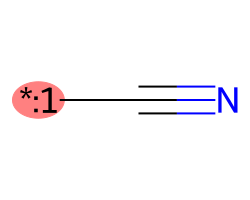

cyanomethyl : [*:1]CC#N


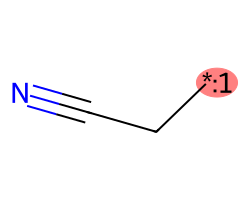

thiol : [*:1]S


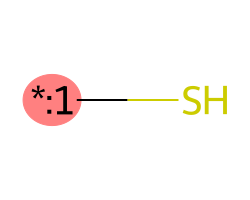

methylthio : [*:1]SC


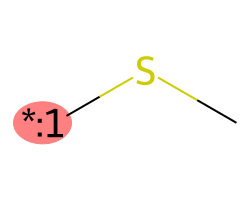

ethylthio : [*:1]SCC


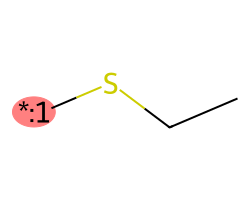

propylthio : [*:1]SCCC


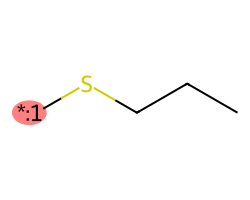

methylsulfoxide : [*:1]S(=O)C


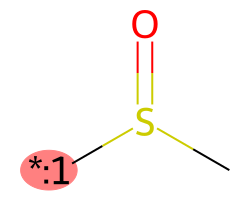

ethylsulfoxide : [*:1]S(=O)CC


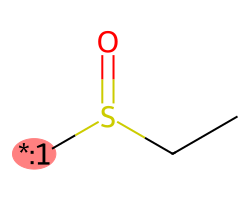

methylsulfone : [*:1]S(=O)(=O)C


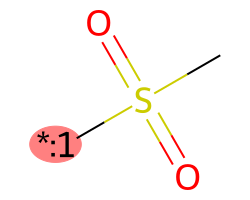

ethylsulfone : [*:1]S(=O)(=O)CC


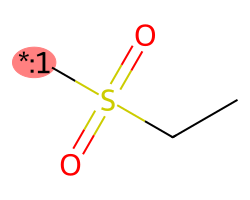

sulfonamide : [*:1]S(=O)(=O)N


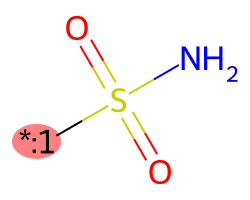

N_methylsulfonamide : [*:1]S(=O)(=O)NC


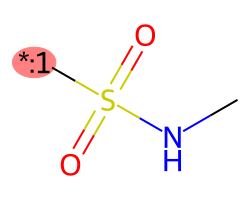

N_ethylsulfonamide : [*:1]S(=O)(=O)NCC


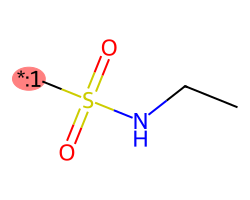

N_N_dimethylsulfonamide : [*:1]S(=O)(=O)N(C)C


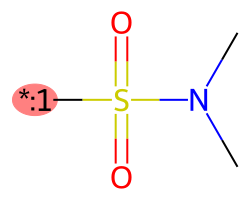

phenyl : [*:1]c1ccccc1


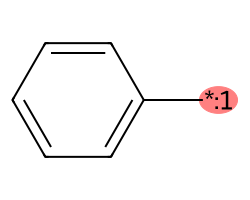

benzyl : [*:1]Cc1ccccc1


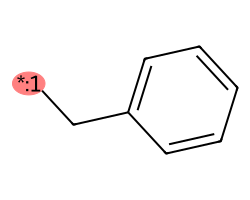

tolyl : [*:1]c1ccc(C)cc1


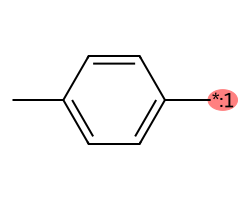

anisyl : [*:1]c1ccc(OC)cc1


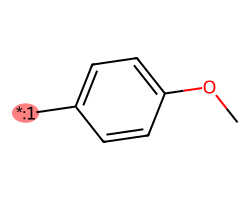

phenoxy : [*:1]Oc1ccccc1


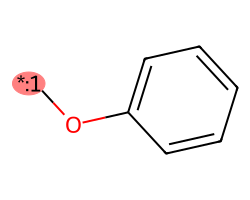

phenethyl : [*:1]CCc1ccccc1


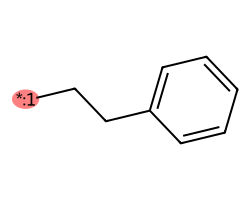

phenylpropyl : [*:1]CCCc1ccccc1


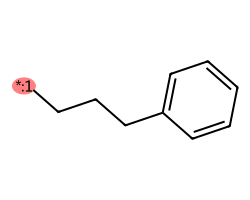

2_fluorophenyl : [*:1]c1ccccc1F


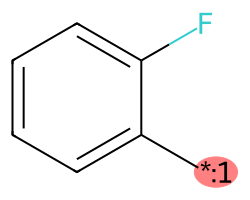

3_fluorophenyl : [*:1]c1cccc(F)c1


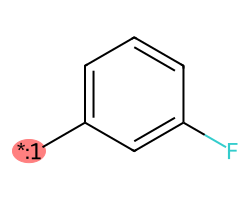

4_fluorophenyl : [*:1]c1ccc(F)cc1


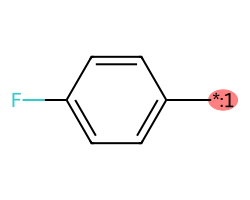

2_chlorophenyl : [*:1]c1ccccc1Cl


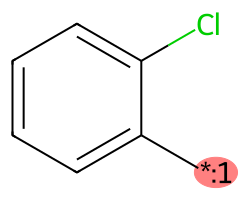

3_chlorophenyl : [*:1]c1cccc(Cl)c1


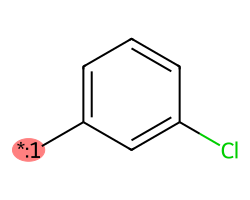

4_chlorophenyl : [*:1]c1ccc(Cl)cc1


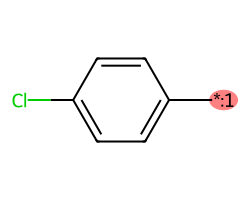

2_bromophenyl : [*:1]c1ccccc1Br


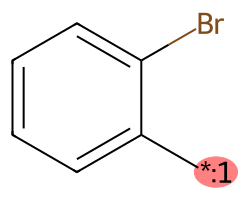

3_bromophenyl : [*:1]c1cccc(Br)c1


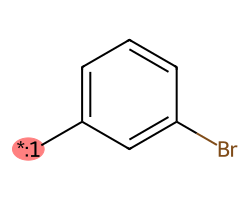

4_bromophenyl : [*:1]c1ccc(Br)cc1


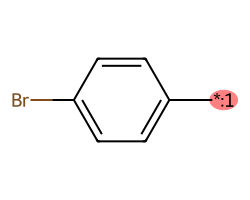

2_methylphenyl : [*:1]c1ccccc1C


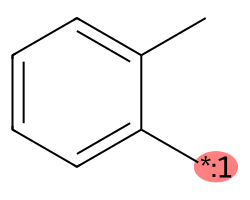

3_methylphenyl : [*:1]c1cccc(C)c1


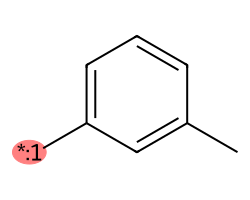

4_methylphenyl : [*:1]c1ccc(C)cc1


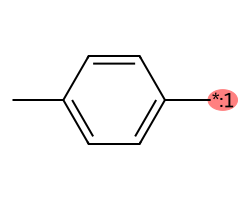

2_methoxyphenyl : [*:1]c1ccccc1OC


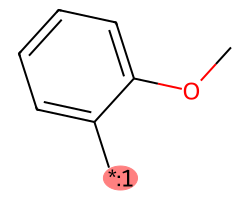

3_methoxyphenyl : [*:1]c1cccc(OC)c1


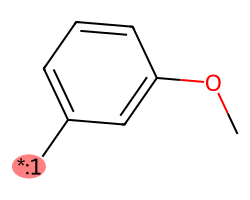

4_methoxyphenyl : [*:1]c1ccc(OC)cc1


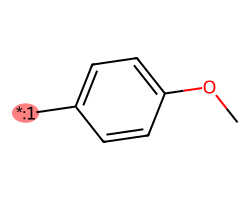

2_hydroxyphenyl : [*:1]c1ccccc1O


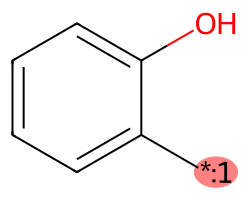

3_hydroxyphenyl : [*:1]c1cccc(O)c1


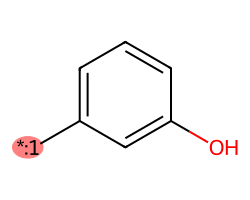

4_hydroxyphenyl : [*:1]c1ccc(O)cc1


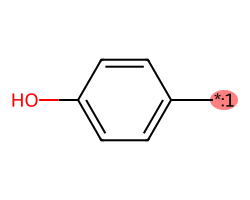

2_trifluoromethylphenyl : [*:1]c1ccccc1C(F)(F)F


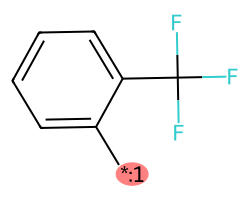

3_trifluoromethylphenyl : [*:1]c1cccc(C(F)(F)F)c1


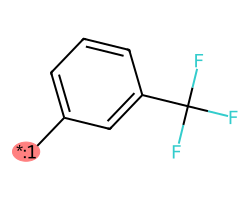

4_trifluoromethylphenyl : [*:1]c1ccc(C(F)(F)F)cc1


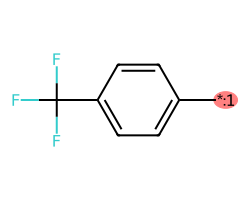

2_aminophenyl : [*:1]c1ccccc1N


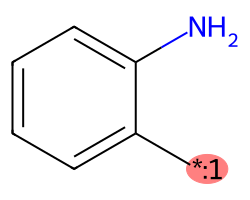

3_aminophenyl : [*:1]c1cccc(N)c1


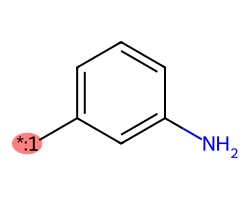

4_aminophenyl : [*:1]c1ccc(N)cc1


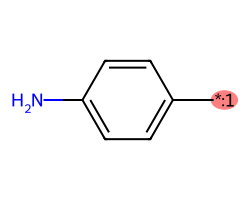

2_pyridyl : [*:1]c1ccccn1


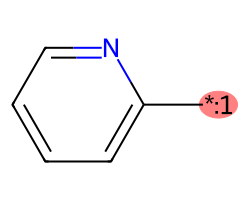

3_pyridyl : [*:1]c1cccnc1


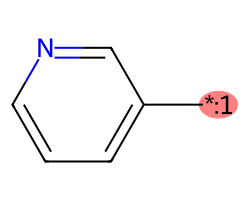

4_pyridyl : [*:1]c1ccncc1


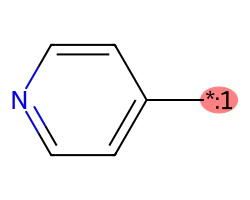

2_pyrimidinyl : [*:1]c1nccnc1


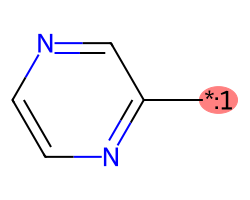

4_pyrimidinyl : [*:1]c1ncc(nc1)


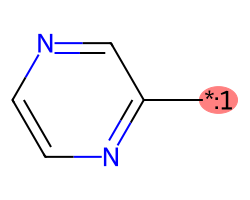

2_pyrazinyl : [*:1]c1cnccn1


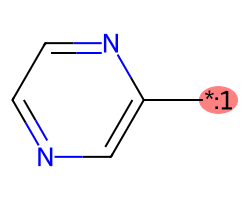

2_pyridazinyl : [*:1]c1nnccc1


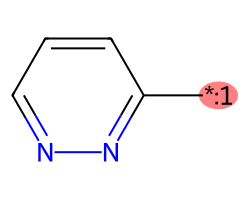

2_furyl : [*:1]c1ccoc1


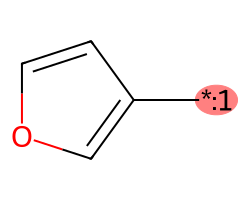

3_furyl : [*:1]c1occc1


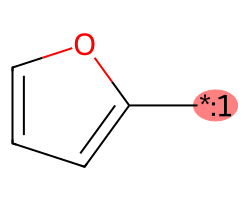

2_thienyl : [*:1]c1ccsc1


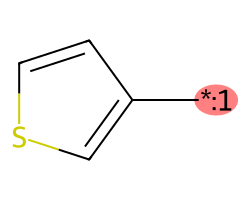

3_thienyl : [*:1]c1sccc1


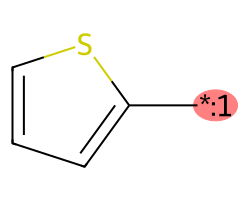

2_thiazolyl : [*:1]c1ncsc1


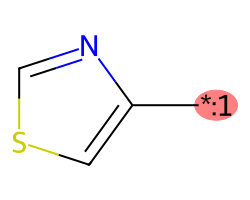

2_oxazolyl : [*:1]c1ncco1


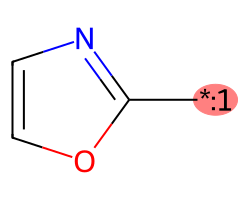

2_imidazolyl : [*:1]c1ncc[nH]1


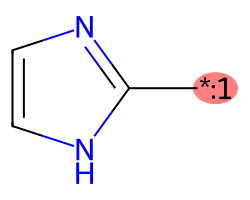

2_pyrazolyl : [*:1]c1n[nH]cc1


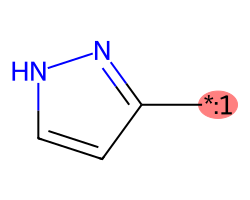

isoxazolyl : [*:1]c1nocc1


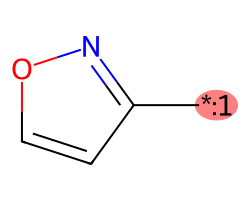

isothiazolyl : [*:1]c1nscc1


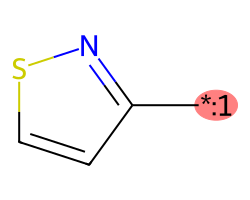

morpholine : [*:1]N1CCOCC1


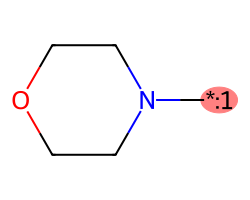

piperidine : [*:1]N1CCCCC1


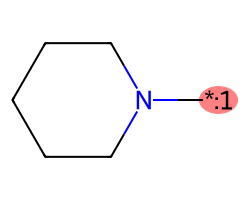

pyrrolidine : [*:1]N1CCCC1


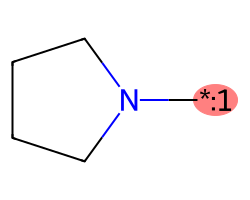

azetidine : [*:1]N1CCC1


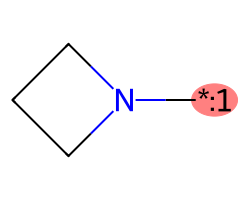

tetrahydrofuran : [*:1]C1CCOC1


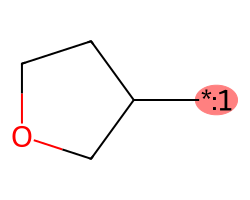

tetrahydropyran : [*:1]C1CCOCC1


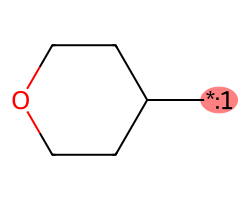

piperazine : [*:1]N1CCNCC1


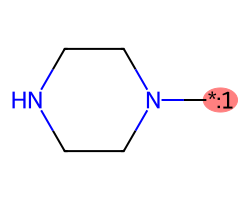

N_methylpiperazine : [*:1]N1CCN(C)CC1


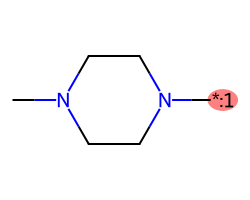

imidazolidine : [*:1]N1CCNC1


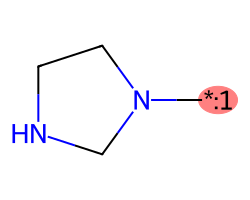

oxazolidine : [*:1]N1CCOC1


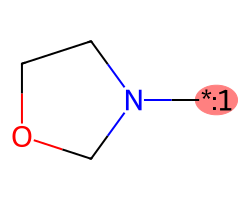

urea : [*:1]NC(=O)N


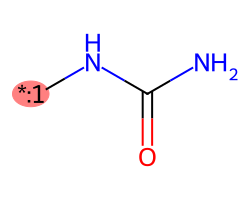

N_methylurea : [*:1]NC(=O)NC


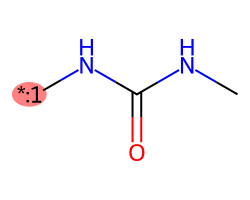

N_N_dimethylurea : [*:1]NC(=O)N(C)C


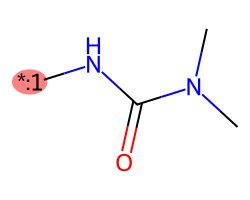

guanidine : [*:1]NC(=N)N


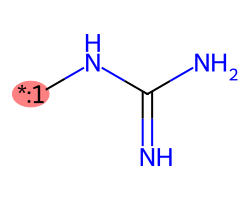

N_methylguanidine : [*:1]NC(=N)NC


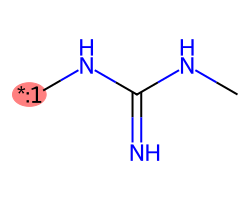

hydrazide : [*:1]C(=O)NN


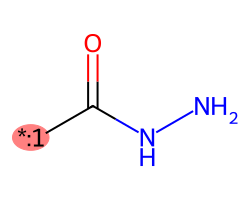

hydroxyl : [*:1]O


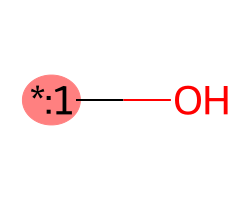

amino : [*:1]N


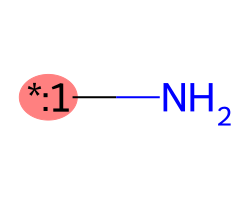

hydroxymethyl : [*:1]CO


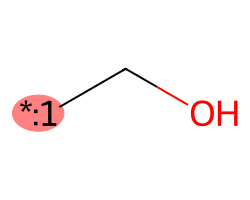

aminomethyl : [*:1]CN


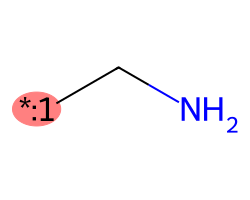

dimethylaminomethyl : [*:1]CN(C)C


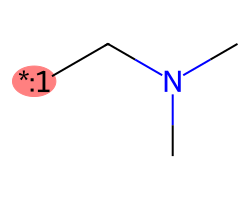

nitro : [*:1][N+](=O)[O-]


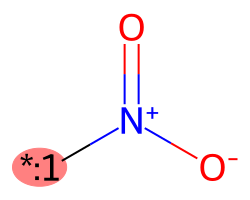

nitroso : [*:1]N=O


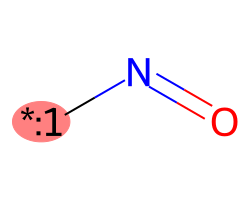

sulfonamide : [*:1]S(=O)(=O)N


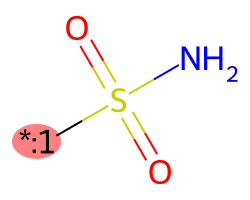

sulfonic_acid : [*:1]S(=O)(=O)O


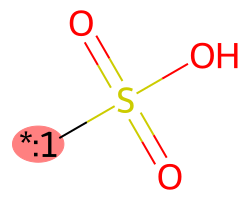

tetrazole : [*:1]c1nnn[nH]1


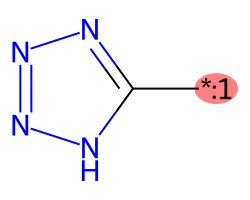

1_2_4_triazole : [*:1]c1nnc[nH]1


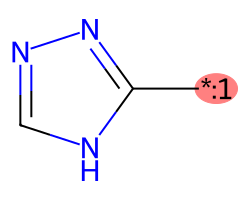

1_2_3_triazole : [*:1]c1nn[nH]c1


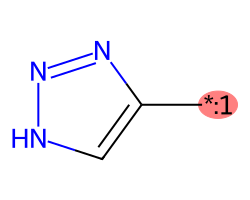

oxadiazole : [*:1]c1nnco1


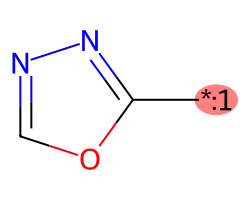

thiadiazole : [*:1]c1nncs1


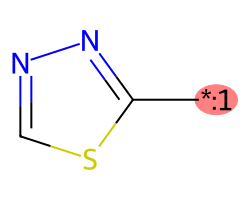

imidazole : [*:1]c1ncc[nH]1


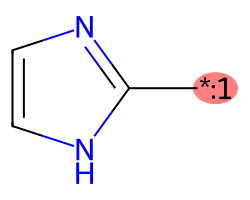

pyrazole : [*:1]c1n[nH]cc1


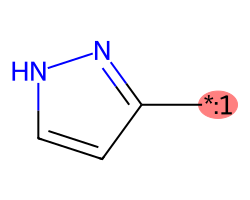

In [45]:
for category, groups in replacement_groups.items():

    for name, smiles in groups.items():

        mol = Chem.MolFromSmiles(smiles)
    
        if mol is None:
            print("Invalid:", name, smiles)
            continue
    
        dummy_atoms = [
            atom.GetIdx()
            for atom in mol.GetAtoms()
            if atom.GetAtomicNum() == 0
        ]
    
        print(name, ":", smiles)
    
        display(
            Draw.MolToImage(
                mol,
                size=(250, 200),
                highlightAtoms=dummy_atoms
            )
        )

Do you wish to automatically generate core: y/n:  y


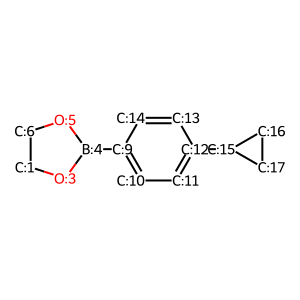

In [46]:
generate_core = input(
    "Do you wish to automatically generate core: y/n: "
)

if generate_core.upper() == "Y":
    core = MurckoScaffold.GetScaffoldForMol(parent_mol)

else:

    core_smiles = input("Enter the smiles of the core molecule")
    core = Chem.MolFromSmiles(core_smiles)

Draw.MolToImage(core)

### Generating fragments/analogues through Fragmentation


-----------------------------
Available molecules:
-----------------------------
0 : Parent

Choose an option:
1 - Fragment a molecule
2 - Replace a bond and create molecular analogues
3 - Display molecules
4 - Finish


Enter choice:  2



Which molecule do you want to modify?
0 : Parent


Enter molecule number:  0



Selected molecule: Parent


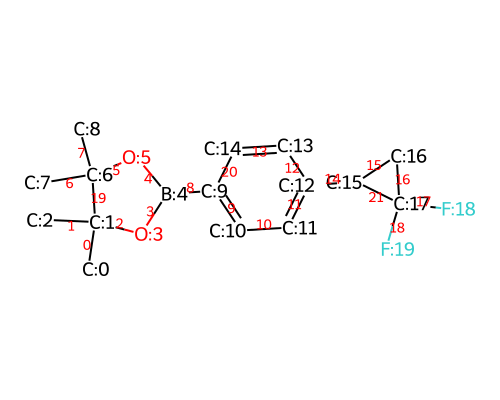

Enter the number of bonds to replace:  1

Enter the bond index of the bond to replace:  0


Core Fragment: *[C:1]1([CH3:2])[O:3][B:4]([c:9]2[cH:10][cH:11][c:12]([CH:15]3[CH2:16][C:17]3([F:18])[F:19])[cH:13][cH:14]2)[O:5][C:6]1([CH3:7])[CH3:8]

-----------------------------
Available molecules:
-----------------------------
0 : Parent

Choose an option:
1 - Fragment a molecule
2 - Replace a bond and create molecular analogues
3 - Display molecules
4 - Finish


Enter choice:  4


-------------------------------------------------------
The generated molecular analogues are given below:
-------------------------------------------------------


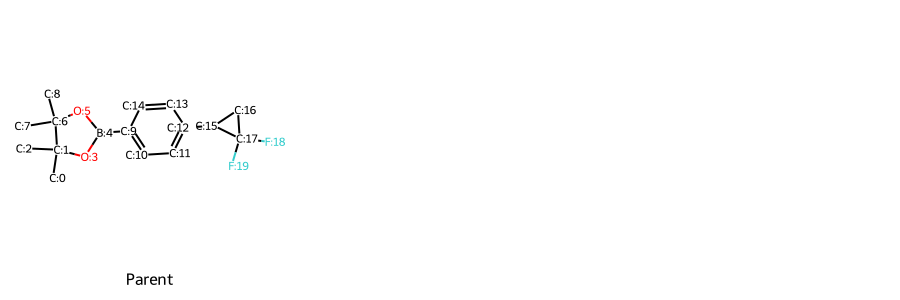

In [64]:
molecule_library = {
    "Parent": parent_mol
}

fragment_library = {}

while True:

    print("\n-----------------------------")
    print("Available molecules:")
    print("-----------------------------")

    for i, name in enumerate(molecule_library.keys()):
        print(i, ":", name)

    print("\nChoose an option:")
    print("1 - Fragment a molecule")
    print("2 - Replace a bond and create molecular analogues")
    print("3 - Display molecules")
    print("4 - Finish")

    choice = input("Enter choice: ")
    
# FINISH
    
    if choice == "4":
        break

# DISPLAY ALL MOLECULES

    if choice == "3":

        names = list(molecule_library.keys())
        molecules = list(molecule_library.values())

        img = Draw.MolsToGridImage(
            molecules,
            molsPerRow=3,
            subImgSize=(300, 300),
            legends=names
        )

        display(img)

        continue

# REPLACE A BOND WITH OTHER SUBSTITUENTS/FRAGMENT A BOND

    if choice == "2" or choice == "1":

        # Select parent molecule from molecule library

        print("\nWhich molecule do you want to modify?")

        names = list(molecule_library.keys())
        molecule_num = []

        for i, name in enumerate(names):
            print(i, ":", name)
            molecule_num.append(i)

        molecule_number = int(
            input("Enter molecule number: ")
        )

        if molecule_number not in molecule_num:
            print("Enter a valid number")

        else:

            parent_name = names[molecule_number]
    
            parent = molecule_library[parent_name]
    
    
# Display selected molecule
    
            print("\nSelected molecule:", parent_name)

            draw_with_original_bond_indices(parent)

## Replace a bond/multiple bonds

            if choice == "2":

                # Ask number of bonds to break

                num_bonds  = int(input("Enter the number of bonds to replace: "))
    
                if num_bonds <= 0:
                    print("Enter atleast one bond")
                    continue
    
                # Ask for bond indices
                bond_indices = []
    
                for i in range(num_bonds):
                    bond_idx = int(input("\nEnter the bond index of the bond to replace: "))
    
                    bond_idx1 = find_current_bond_idx(parent, bond_idx)
                
        
                    # Check whether bond exists between the selected atoms
    
                    bond = parent.GetBondWithIdx(bond_idx1)
        
                    if bond is None:
        
                        print("\nNo bond exists between these atoms.")
        
                        continue 
    
                    bond_indices.append(bond_idx1)
                
                    
                    # Fragment the bond
        
                    fragmented_mol = Chem.FragmentOnBonds(parent, bond_indices)
        
                    # Fragmenting the molecule
        
                    fragments = Chem.GetMolFrags(fragmented_mol, asMols=True)
                
# Fragmenting the molecule                
               
            if choice == "1":

                atom1_idx = int(input("\nEnter first atom index of bond: "))
    
                atom2_idx = int(input("Enter second atom index of bond: "))

                idx1 = find_current_idx(parent, atom1_idx)
                idx2 = find_current_idx(parent, atom2_idx)
    
                # Check whether bond exists between the selected atoms
  
                bond = parent.GetBondBetweenAtoms(idx1, idx2)
    
                if bond is None:
    
                    print("\nNo bond exists between these atoms.")
    
                    continue

                # Make editable copy

                rw_mol = Chem.RWMol(parent)  

                # Break bond

                rw_mol.RemoveBond(idx1,idx2)

                # Sanitize
    
                try:
    
                    Chem.SanitizeMol(rw_mol)
    
                except Exception as e:
    
                    print("\nSanitization failed:")
                    print(e)
    
                    continue

                # Fragmenting the molecule

                fragments = Chem.GetMolFrags(rw_mol, asMols=True)

# Identify the core fragment
            
            core_fragment = None
            side_fragment = None

            for frag in fragments:

                if frag.HasSubstructMatch(core):
                    core_fragment = frag
                else:
                    side_fragment = frag

            if core_fragment is None:
                raise ValueError("Core was not found in either fragment.")
           
            fragment_smiles = Chem.MolToSmiles(core_fragment)
            print(f"Core Fragment: {fragment_smiles}")

            already_exists = False

            if choice == "2":

                for existing_mol in fragment_library.values():
        
                    existing_smiles = Chem.MolToSmiles(
                            existing_mol
                    )
        
                    if existing_smiles == fragment_smiles:
        
                        already_exists = True
                        break
        
                # ---------------------------------------------
                # Add new fragment to the fragment_library
                # ---------------------------------------------
        
                if not already_exists:
                    analogue_name = (
                    f"{parent_name}_break_"
                    f"{bond_idx}_bond"
                    )

                fragment_library[analogue_name] = core_fragment
    
            else:

                for existing_mol in molecule_library.values():
        
                    existing_smiles = Chem.MolToSmiles(
                            existing_mol
                    )
        
                    if existing_smiles == fragment_smiles:
        
                        already_exists = True
                        break
        
                # ---------------------------------------------
                # Add new fragment to the fragment_library
                # ---------------------------------------------
                if not already_exists:
                    analogue_name = (
                    f"{parent_name}_break_"
                    f"{atom1_idx}_{atom2_idx}"
                    )
                    
    
                molecule_library[analogue_name] = core_fragment
   
# Display Molecular analogues
print("-------------------------------------------------------")
print("The generated molecular analogues are given below:")
print("-------------------------------------------------------")

names = list(molecule_library.keys())
molecules = list(molecule_library.values())

display(Draw.MolsToGridImage(molecules,
                             legends = names,
                              molsPerRow = 3,
                             subImgSize = (300,300),
                             )
            )


In [49]:
categories = list(replacement_groups.keys())

In [65]:
def select_categories(dummy_number):

    print(f"\nSelect categories for dummy neighbor {dummy_number}")
    print("-------------------------------------------")

    for i, name in enumerate(categories):
        print(f"{i} | {name}")

    choices = input(
        "Enter 3-4 category numbers separated by commas: "
    )

    selected_indices = [
        int(x.strip()) for x in choices.split(",")
    ]

    selected_categories = [
        categories[i] for i in selected_indices
    ]

    print("Selected categories:", selected_categories)

    return selected_categories

In [66]:
def collect_replacements(selected_categories):

    selected_groups = {}

    for category in selected_categories:

        for name, smiles in replacement_groups[category].items():

            selected_groups[name] = smiles

    return selected_groups

In [68]:
def prepare_replacement_groups(selected_groups):

    prepared = []

    for name, smiles in selected_groups.items():

        mol = Chem.MolFromSmiles(smiles)

        prepared.append({
            "name": name,
            "smiles": smiles,
            "mol": mol
        })

    return prepared

In [70]:
def attach_replacement(core, replacement, core_dummy_neighbor_original_idx):

    """
    Attach one replacement group to a selected position in the core.

    core_neighbor_original_idx:
        Original index of the core atom neighbouring the dummy.

    The replacement group must contain exactly one dummy atom,
    and that dummy must have exactly one neighbour.
    """

    # --------------------------------------------------
    # 1. Find the correct dummy in the current core
    # --------------------------------------------------

    core_info = get_core_dummy_info(core)

    matching_dummies = [
        info
        for info in core_info
        if info["core_dummy_neighbor_original_idx"]
        == core_dummy_neighbor_original_idx
    ]

    if len(matching_dummies) != 1:
        raise ValueError(
            f"Expected one dummy at original neighbour index "
            f"{core_dummy_neighbor_original_idx}, "
            f"but found {len(matching_dummies)}."
        )

    selected_dummy = matching_dummies[0]

    core_dummy_idx = selected_dummy["core_dummy_current_idx"]

    core_neighbor_idx = selected_dummy[
        "core_dummy_neighbor_current_idx"
    ]

    # --------------------------------------------------
    # 2. Find the replacement dummy and its neighbour
    # --------------------------------------------------

    replacement_dummies = [
        atom for atom in replacement.GetAtoms()
        if atom.GetAtomicNum() == 0
    ]

    if len(replacement_dummies) != 1:
        raise ValueError(
            "Replacement must contain exactly one dummy atom."
        )

    replacement_dummy = replacement_dummies[0]

    replacement_neighbors = list(
        replacement_dummy.GetNeighbors()
    )

    if len(replacement_neighbors) != 1:
        raise ValueError(
            "Replacement dummy must have exactly one neighbour."
        )

    replacement_dummy_idx = replacement_dummy.GetIdx()

    replacement_neighbor_idx = replacement_neighbors[0].GetIdx()

    # --------------------------------------------------
    # 3. Combine the molecules
    # --------------------------------------------------

    offset = core.GetNumAtoms()

    combined = Chem.CombineMols(core, replacement)

    rw_mol = Chem.RWMol(combined)

    # Replacement indices change after combining
    replacement_dummy_idx += offset
    replacement_neighbor_idx += offset

    # --------------------------------------------------
    # 4. Connect the two attachment atoms
    # --------------------------------------------------

    rw_mol.AddBond(
        core_neighbor_idx,
        replacement_neighbor_idx,
        Chem.BondType.SINGLE
    )

    # --------------------------------------------------
    # 5. Remove both dummy atoms
    # --------------------------------------------------

    dummy_indices = [
        core_dummy_idx,
        replacement_dummy_idx
    ]

    # Remove higher index first to avoid index-shifting errors
    for idx in sorted(dummy_indices, reverse=True):
        rw_mol.RemoveAtom(idx)

    # --------------------------------------------------
    # 6. Convert to a normal RDKit molecule
    # --------------------------------------------------

    new_mol = rw_mol.GetMol()

    Chem.SanitizeMol(new_mol)

    return new_mol

-------------------------------------------------------
The generated fragments are given below:
-------------------------------------------------------


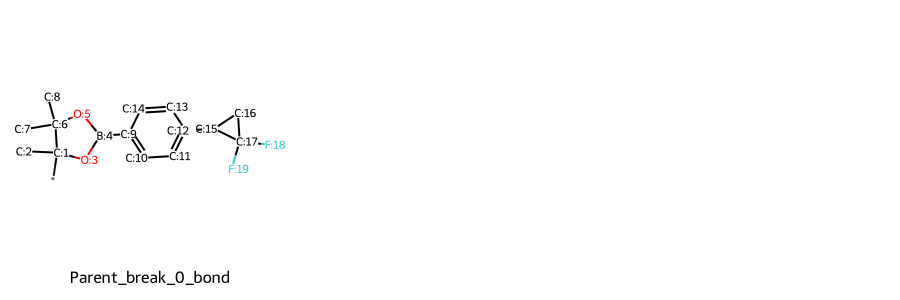

-------------------------------------------------------------------
Select the replacement groups for the different generated fragments
-------------------------------------------------------------------

Fragment 1


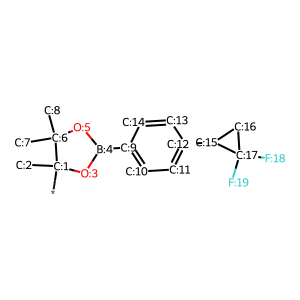


Select categories for dummy neighbor 1
-------------------------------------------
0 | alkyl
1 | cycloalkyl
2 | alkenyl_alkynyl
3 | halogens
4 | fluoroalkyl
5 | alkoxy
6 | fluoroalkoxy
7 | oxygen
8 | amines
9 | amides
10 | carbonyl
11 | nitrile
12 | sulfur
13 | phenyl
14 | halophenyl
15 | substituted_phenyl
16 | pyridyl
17 | diazines
18 | five_membered_heteroaryl
19 | saturated_heterocycles
20 | nitrogen_carbonyl
21 | polar_groups
22 | bioisosteres


Enter 3-4 category numbers separated by commas:  0,1


Selected categories: ['alkyl', 'cycloalkyl']
--------------------------------------------------------------------------------------------------

All fragment selections completed.


In [71]:
# Display generated fragements
print("-------------------------------------------------------")
print("The generated fragments are given below:")
print("-------------------------------------------------------")

names = list(fragment_library.keys())
molecules = list(fragment_library.values())

display(Draw.MolsToGridImage(molecules,
                             legends = names,
                              molsPerRow = 3,
                             subImgSize = (300,300),
                             )
            )  

molecule_selections = {}

print("-------------------------------------------------------------------")
print("Select the replacement groups for the different generated fragments")
print("-------------------------------------------------------------------")

for mol_idx, molecule in enumerate(molecules):

    print(f"\nFragment {mol_idx + 1}")

    display(Draw.MolToImage(molecule))

    core_info = get_core_dummy_info(molecule)

    selected_categories = {}

    for dummy in core_info:

        core_neighbor_idx = dummy["core_dummy_neighbor_original_idx"]
    
        core_idx_categories = select_categories(core_neighbor_idx)
    
        # Collect selected replacement groups
        selected_groups = collect_replacements(core_idx_categories)
    
        # Validate and prepare RDKit molecules
        prepared_groups = prepare_replacement_groups(selected_groups)
    
        # Store separately for each dummy position
        selected_categories[core_neighbor_idx] = prepared_groups
       

    # Store all selections for this fragment
    molecule_selections[mol_idx] = selected_categories

    print("--------------------------------------------------------------------------------------------------")

print("\nAll fragment selections completed.")
        
        



In [72]:
from itertools import product

analogue_library = {}

for mol_idx, position_groups in molecule_selections.items():

    # Retrieve the original fragment
    molecule = molecules[mol_idx]

    # Original neighbour indices of selected positions
    positions = list(position_groups.keys())

    # Replacement groups available for each position
    replacement_lists = list(position_groups.values())

    # Generate every possible combination
    combinations = product(*replacement_lists)

    print(f"\nGenerating analogues for Fragment {mol_idx + 1}")

    for combination_idx, combination in enumerate(combinations, start=1):

        # Always begin with a fresh copy of the original fragment
        current_mol = Chem.Mol(molecule)

        replacement_names = []

        try:

            # Attach one replacement group at a time
            for position, replacement_info in zip(positions, combination):

                replacement_name = replacement_info["name"]

                replacement_mol = replacement_info["mol"]

                current_mol = attach_replacement(
                    current_mol,
                    replacement_mol,
                    position
                )

                replacement_names.append(replacement_name)

            # Store the completed analogue
            analogue_name = (
                f"Fragment_{mol_idx + 1}_"
                f"Analogue_{combination_idx}"
            )
            analogue_library[analogue_name] = current_mol
            molecule_library[analogue_name] = current_mol ### adding it to the molecule library which contains the parent mol 
                                                          ### and fragments previously generated from the parent molecule

            # print(
            #     analogue_name,
            #     "|",
            #     replacement_names,
            #     "|",
            #     Chem.MolToSmiles(current_mol)
            # )

        except (ValueError, Chem.rdchem.MolSanitizeException) as e:

            print(
                f"Skipping combination {combination_idx}: {e}"
            )


Generating analogues for Fragment 1


-------------------------------------------------------
Generated Molecular Analogues
-------------------------------------------------------
Total generated analogues: 24


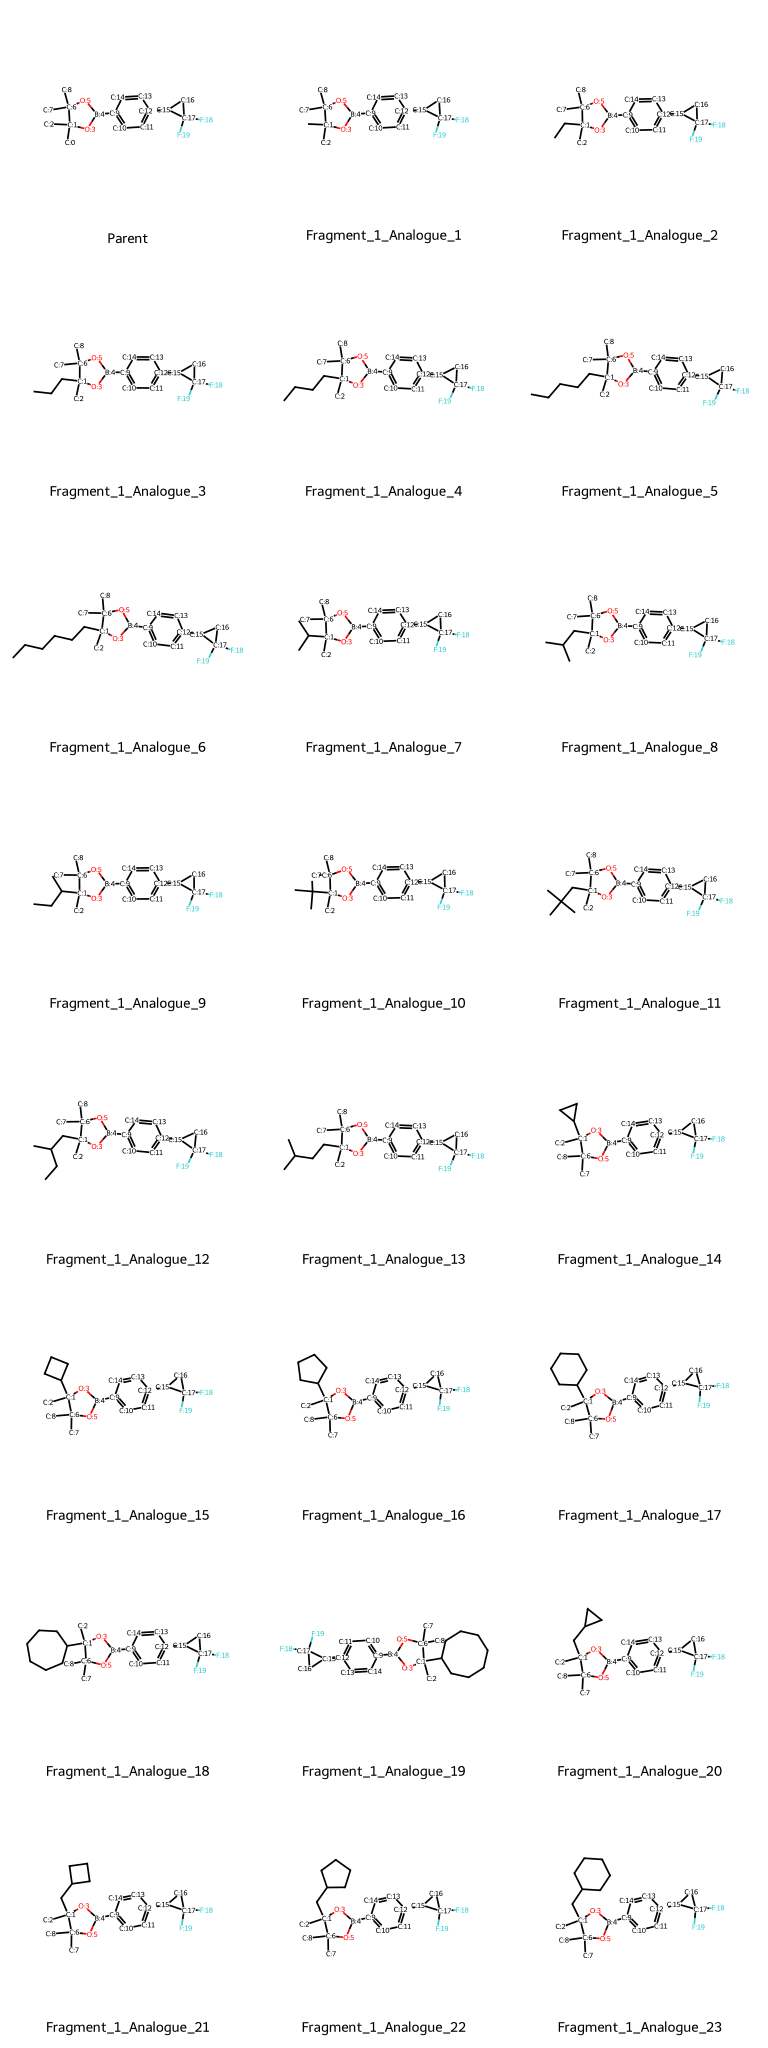

In [73]:
print("-------------------------------------------------------")
print("Generated Molecular Analogues")
print("-------------------------------------------------------")

analogue_names = list(molecule_library.keys())
analogue_molecules = list(molecule_library.values())

print(f"Total generated analogues: {len(analogue_molecules)}")

# Create fresh copies for drawing
drawing_molecules = []

for mol in analogue_molecules:

    mol_copy = Chem.Mol(mol)

    # Remove existing conformers and regenerate 2D coordinates
    mol_copy.RemoveAllConformers()

    rdDepictor.Compute2DCoords(mol_copy)

    drawing_molecules.append(mol_copy)

# Display
if drawing_molecules:

    display(
        Draw.MolsToGridImage(
            drawing_molecules,
            legends=analogue_names,
            molsPerRow=3,
            subImgSize=(300, 300),
            maxMols=len(drawing_molecules),
            useSVG=True
        )
    )

In [78]:
from rdkit import Chem

def remove_atom_map_labels(mol):
    mol = Chem.Mol(mol)  # Keep the original molecule unchanged

    for atom in mol.GetAtoms():
        atom.SetAtomMapNum(0)

    return mol

In [77]:
from rdkit import Chem

unique_molecules = {}

for mol in analogue_molecules:
    if mol is None:
        continue

    smiles = Chem.MolToSmiles(remove_atom_map_labels(
        mol,
        canonical=True,
        isomericSmiles=True
    )

    unique_molecules.setdefault(smiles, name)

    print(smiles)

print("Generated:", len(analogue_molecules))
print("Unique structures:", len(unique_molecules))

[CH3:0][C:1]1([CH3:2])[O:3][B:4]([c:9]2[cH:10][cH:11][c:12]([CH:15]3[CH2:16][C:17]3([F:18])[F:19])[cH:13][cH:14]2)[O:5][C:6]1([CH3:7])[CH3:8]
C[C:1]1([CH3:2])[O:3][B:4]([c:9]2[cH:10][cH:11][c:12]([CH:15]3[CH2:16][C:17]3([F:18])[F:19])[cH:13][cH:14]2)[O:5][C:6]1([CH3:7])[CH3:8]
CC[C:1]1([CH3:2])[O:3][B:4]([c:9]2[cH:10][cH:11][c:12]([CH:15]3[CH2:16][C:17]3([F:18])[F:19])[cH:13][cH:14]2)[O:5][C:6]1([CH3:7])[CH3:8]
CCC[C:1]1([CH3:2])[O:3][B:4]([c:9]2[cH:10][cH:11][c:12]([CH:15]3[CH2:16][C:17]3([F:18])[F:19])[cH:13][cH:14]2)[O:5][C:6]1([CH3:7])[CH3:8]
CCCC[C:1]1([CH3:2])[O:3][B:4]([c:9]2[cH:10][cH:11][c:12]([CH:15]3[CH2:16][C:17]3([F:18])[F:19])[cH:13][cH:14]2)[O:5][C:6]1([CH3:7])[CH3:8]
CCCCC[C:1]1([CH3:2])[O:3][B:4]([c:9]2[cH:10][cH:11][c:12]([CH:15]3[CH2:16][C:17]3([F:18])[F:19])[cH:13][cH:14]2)[O:5][C:6]1([CH3:7])[CH3:8]
CCCCCC[C:1]1([CH3:2])[O:3][B:4]([c:9]2[cH:10][cH:11][c:12]([CH:15]3[CH2:16][C:17]3([F:18])[F:19])[cH:13][cH:14]2)[O:5][C:6]1([CH3:7])[CH3:8]
CC(C)[C:1]1([CH3:2])[O:3][B

In [74]:
import pandas as pd
import time

results = []

for mol in analogue_molecules:

    smiles = Chem.MolToSmiles(mol)

    pubchem_result = check_pubchem(smiles)

    pubchem_result["Analogue"] = name

    results.append(pubchem_result)

    time.sleep(0.4)

df = pd.DataFrame(results)

display(df[:20])

,SMILES,Status,CID,PubChem_URL,Analogue
0,[CH3:0][C:1]1([CH3:2])[O:3][B:4]([c:9]2[cH:10]...,Found,[142362364],[https://pubchem.ncbi.nlm.nih.gov/compound/142...,Parent
1,C[C:1]1([CH3:2])[O:3][B:4]([c:9]2[cH:10][cH:11...,Found,[142362364],[https://pubchem.ncbi.nlm.nih.gov/compound/142...,Parent
2,CC[C:1]1([CH3:2])[O:3][B:4]([c:9]2[cH:10][cH:1...,Not found in PubChem,None,None,Parent
3,CCC[C:1]1([CH3:2])[O:3][B:4]([c:9]2[cH:10][cH:...,Not found in PubChem,None,None,Parent
4,CCCC[C:1]1([CH3:2])[O:3][B:4]([c:9]2[cH:10][cH...,Not found in PubChem,None,None,Parent
5,CCCCC[C:1]1([CH3:2])[O:3][B:4]([c:9]2[cH:10][c...,Not found in PubChem,None,None,Parent
6,CCCCCC[C:1]1([CH3:2])[O:3][B:4]([c:9]2[cH:10][...,Not found in PubChem,None,None,Parent
7,CC(C)[C:1]1([CH3:2])[O:3][B:4]([c:9]2[cH:10][c...,Not found in PubChem,None,None,Parent
8,CC(C)C[C:1]1([CH3:2])[O:3][B:4]([c:9]2[cH:10][...,Not found in PubChem,None,None,Parent
9,CCC(C)[C:1]1([CH3:2])[O:3][B:4]([c:9]2[cH:10][...,Not found in PubChem,None,None,Parent
